# Chern numbers of magnon and exciton bands

The collective modes of a mean-field state have bands too, and a band of modes that is separated from the others has a Chern number. We will now see it for two kinds of modes: a magnon of time-dependent Hartree-Fock in a ferromagnet, and a Frenkel exciton of the Bethe-Salpeter equation. In both cases a mode at momentum $\mathbf Q$ is a sum of electron-hole pairs, an electron at $\mathbf k+\mathbf Q$ and a hole at $\mathbf k$, with the amplitudes $X_{vc}(\mathbf k)$. Written in the orbitals,

$$\Phi_{\mathbf Q}(\mathbf k;\alpha,\beta)=\sum_{vc}X_{vc}(\mathbf k)\,u_{c,\mathbf k+\mathbf Q}(\alpha)\,u^*_{v,\mathbf k}(\beta),$$

it does not depend on the phases of the Bloch states $u_{n,\mathbf k}$, so it plays the role of the Bloch state of a band. The Chern number is the sum of its Berry fluxes $F_\square$ through the plaquettes of a mesh of $\mathbf Q$, $C=\frac{1}{2\pi}\sum_\square F_\square$, with the sign of `h.get_chern()`.

### Import the necessary libraries

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import geometry
from pyqula.multihopping import MultiHopping
from pyqula.bsetk.interaction import density_interaction

### The magnon bands of a ferromagnet

We take the honeycomb lattice with a second-neighbor hopping $t'=0.3t$, a Kane-Mele spin-orbit coupling $\lambda=0.15t$ and a Zeeman field $B=3t$, with $U=8t$ at half filling. The field polarizes the magnet along $-z$ and gives the magnons a gap, and the product of $\lambda$ and $t'$ acts as a Dzyaloshinskii-Moriya interaction for the magnons. The mean field and the magnon problem share the k-mesh `nk`.

Sz per site [-1. -1.]
bands [0] C = 1.0
bands [1] C = -1.0
bands [0, 1] C = 0.0


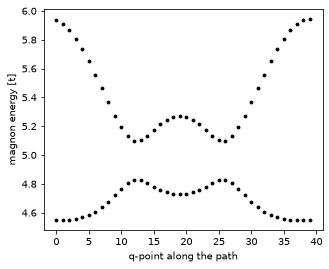

In [2]:
nk = 8 # the mean field and the magnons share this mesh
g = geometry.honeycomb_lattice()
h = g.get_hamiltonian(tij=[1.0,0.3]) # first and second neighbor hopping
h.add_kane_mele(0.15) # spin-orbit coupling, conserves Sz
h.add_zeeman([0.,0.,3.0]) # the field gaps the magnons
hmf = h.get_mean_field_hamiltonian(U=8.0,filling=0.5,mf="ferro",nk=nk)
print("Sz per site",np.round(hmf.get_vev("sz").real,6))
for bands in [[0],[1],[0,1]]:
    c = hmf.get_magnon_chern(bands=bands,nq=8,nk=nk)
    print("bands",bands,"C =",np.round(c,8))
qs,es = hmf.get_magnon_bands(method="tdhf",nk=nk,nq=40,n=2) # along a path
plt.figure(figsize=(5,4))
plt.scatter(qs,es.real,c="black",s=8)
plt.xlabel("q-point along the path") ; plt.ylabel("magnon energy [t]")
plt.show()

The magnet is saturated, with $S_z=-1$ on both sites. The lower magnon band has $C=+1$, the upper one $C=-1$, and the two together $C=0$. The path goes $\Gamma$, K, M, K', $\Gamma$: the lower band starts at $4.55t$ at $\Gamma$ and has its maximum at K and K', where the upper band has its minimum, about $5.1t$. This is where the two bands come closest.

band 0 C = 1.0 | gap 0.2642 | bound 2.7524 | largest flux / pi 0.1018
band 1 C = -1.0 | gap 0.2642 | bound 1.893 | largest flux / pi 0.101


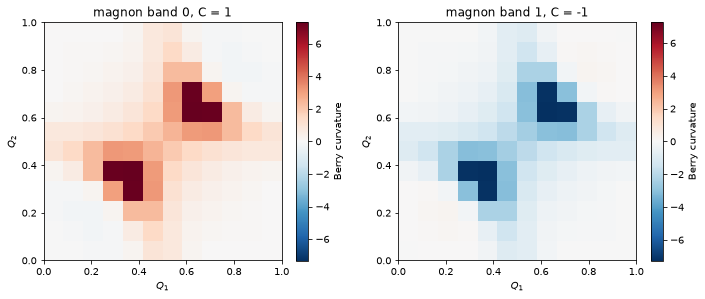

In [3]:
nq = 12 # the mesh of Q
fig,axs = plt.subplots(1,2,figsize=(10,4))
for ax,band in zip(axs,[0,1]):
    r = hmf.get_magnon_chern(bands=[band],nq=nq,nk=nk,full_output=True)
    print("band",band,"C =",np.round(r.chern,8),"| gap",np.round(r.gap,4),
          "| bound",np.round(r.bound,4),"| largest flux / pi",np.round(r.max_flux/np.pi,4))
    curvature = r.fluxes*nq**2/(2.*np.pi) # its mean over the zone is C
    vmax = np.max(np.abs(curvature))
    im = ax.imshow(curvature.T,origin="lower",extent=[0,1,0,1],cmap="RdBu_r",vmin=-vmax,vmax=vmax)
    ax.set_xlabel("$Q_1$") ; ax.set_ylabel("$Q_2$")
    ax.set_title("magnon band "+str(band)+", C = "+str(int(round(r.chern))))
    plt.colorbar(im,ax=ax,label="Berry curvature")
plt.tight_layout()
plt.show()

The map is the Berry curvature, the flux of each plaquette times the number of plaquettes over $2\pi$, so its mean over the zone is $C$. The curvature of the lower band is positive and sits around K and K', at $(1/3,1/3)$ and $(2/3,2/3)$, where the two bands are closest: on this mesh the gap between them is $0.26t$. The upper band has the opposite curvature at the same points. The largest flux of a plaquette is $0.10\pi$, far below $\pi$, and `bound` says that the bands are $2.75t$ and $1.89t$ below the Stoner continuum, so the mesh resolves the bands and the integers can be trusted.

### A Frenkel exciton with a Chern number

A Frenkel exciton is an excitation that hops from molecule to molecule. We take the kagome lattice and keep only the hoppings inside the up triangles, so each triangle is a molecule with three levels, the lowest one filled, and we thread a flux $\phi$ through each triangle. A density interaction $V_1=1$ between neighbors binds the electron and the hole on one molecule and moves the bound pair to the next molecules.

In [4]:
def frenkel(phi):
    """Kagome lattice of decoupled up triangles with a flux phi"""
    H = np.zeros((3,3),dtype=np.complex128) # one up triangle, a molecule
    for (i,j) in [(0,1),(1,2),(2,0)]:
        H[j,i] = -np.exp(1j*phi/3.) # hopping with a Peierls phase
        H[i,j] = np.conj(H[j,i])
    H += 0.5*np.identity(3) # one level below the Fermi energy, two above
    h = geometry.kagome_lattice().get_hamiltonian(has_spin=False)
    h.set_multihopping(MultiHopping({(0,0,0):H})) # hopping in the cell only
    return h

for phi in [-0.6,-0.3,0.,0.3,0.6]:
    h = frenkel(phi)
    W = density_interaction(h,V1=1.0) # density interaction between neighbors
    try:
        c = h.get_exciton_chern(bands=[0],nq=6,V=W,nk=4,tda=True)
        print("phi",phi,"C =",np.round(c,8))
    except ValueError: # the two lowest excitons touch
        print("phi",phi,"the lowest exciton touches the next one")

phi -0.6 C = 1.0
phi -0.3 C = 1.0
phi 0.0 the lowest exciton touches the next one
phi 0.3 C = -1.0
phi 0.6 C = -1.0


The flux $\phi=0.3$ and $0.6$ gives $C=-1$ for the lowest exciton band, and the opposite flux gives $C=+1$. With no flux the molecule has time-reversal symmetry, the two lowest excitons touch at $\mathbf Q=0$, and the calculation raises an error instead of returning an integer. Each point of the mesh is one Bethe-Salpeter calculation, so a coarse mesh, `nq=6` and `nk=4`, is enough for the scan.

C = -1.0 | gap 0.3362 | bound 0.9875 | largest flux / pi 0.0627


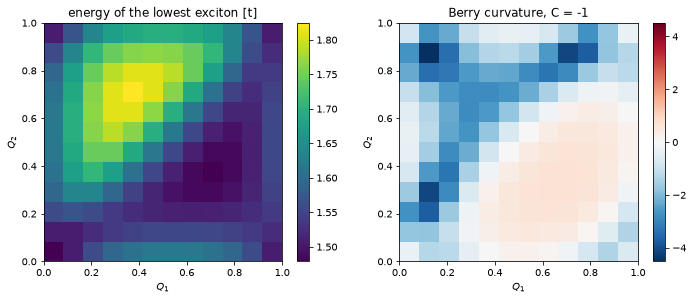

In [5]:
h = frenkel(0.3)
W = density_interaction(h,V1=1.0)
nq = 12
r = h.get_exciton_chern(bands=[0],nq=nq,V=W,nk=6,tda=True,full_output=True)
print("C =",np.round(r.chern,8),"| gap",np.round(r.gap,4),"| bound",np.round(r.bound,4),
      "| largest flux / pi",np.round(r.max_flux/np.pi,4))
fig,axs = plt.subplots(1,2,figsize=(10,4))
im = axs[0].imshow(r.energies[:,:,0].T,origin="lower",extent=[0,1,0,1],cmap="viridis")
axs[0].set_title("energy of the lowest exciton [t]")
plt.colorbar(im,ax=axs[0])
curvature = r.fluxes*nq**2/(2.*np.pi) # its mean over the zone is C
vmax = np.max(np.abs(curvature))
im = axs[1].imshow(curvature.T,origin="lower",extent=[0,1,0,1],cmap="RdBu_r",vmin=-vmax,vmax=vmax)
axs[1].set_title("Berry curvature, C = "+str(int(round(r.chern))))
plt.colorbar(im,ax=axs[1])
for ax in axs: ax.set_xlabel("$Q_1$") ; ax.set_ylabel("$Q_2$")
plt.tight_layout()
plt.show()

The exciton band goes from $1.48t$, around $\Gamma$ at the corners of the map, to $1.82t$. It has a second minimum around $(2/3,1/3)$. The Berry curvature is negative in a broad region around $\Gamma$, at the corners and along the edges of the map, and weakly positive around $(2/3,1/3)$. With no flux the two lowest excitons touch at $\Gamma$. The gap to the next exciton is $0.34t$ on this mesh, and the band is $0.99t$ below the lowest electron-hole transition, so it is a bound exciton isolated over the whole zone. The same calculation for the magnon of the local moments of a Kondo lattice is in the user guide, in the chapter on the pseudofermion mean field.